In [1]:
import re
import numpy as np
import pandas as pd
from pprint import pprint
import gensim
import gensim.corpora as corpora
from gensim.models import CoherenceModel
from gensim.utils import simple_preprocess
from gensim.models.ldamodel import LdaModel
import nltk
from nltk.corpus import stopwords
from collections import Counter, defaultdict
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
def load_pottery_data(filename, culture_name):
    documents = []
    with open(filename, 'r') as f:
        for line_num, line in enumerate(f, 1):
            triplets = re.findall(r"\('([^']+)', '([^']+)', '([^']+)'\)", line.strip())
            if triplets:
                doc_triplets = [f"({t[0]}, {t[1]}, {t[2]})" for t in triplets]
                documents.append({
                    'vessel_id': f"{culture_name}_{line_num}",
                    'culture': culture_name,
                    'triplets': doc_triplets,
                    'triplets_text': ' '.join(doc_triplets),
                    'num_triplets': len(doc_triplets)
                })
    return documents

# Load all cultural datasets
print("Loading archaeological datasets...")
cw_docs = load_pottery_data('./data/clustered_paths_CW.csv', 'CW')
mi_docs = load_pottery_data('./data/clustered_paths_MI.csv', 'MI')
efg_docs = load_pottery_data('./data/clustered_paths_EFG.csv', 'EFG')
lfg_docs = load_pottery_data('./data/clustered_paths_LFG.csv', 'LFG')
fbw_docs = load_pottery_data('./data/clustered_paths_FBW.csv', 'FBW')
print("Datasets loaded.")

print(f"Dataset summary:")
print(f"  CW (Corded Ware): {len(cw_docs)} vessels")
print(f"  MI (Middle phase): {len(mi_docs)} vessels")
print(f"  EFG (Early/Final phase): {len(efg_docs)} vessels")
print(f"  LFG (Late phase): {len(lfg_docs)} vessels")

# All docs are combined to create the corpus, from the overall corpus we extract the clusters and topics later and compare at the end the distribution of words in each culture 
# extracting the empirical frequencies from the data from each separate culture and the one obtained from the topic modeling from the whole pool

NUM_CULTURES = 4

if NUM_CULTURES == 4:
    all_docs = cw_docs[:-2] + mi_docs[:-2] + efg_docs[:-2] + lfg_docs[:-2]
elif NUM_CULTURES == 2:
    all_docs = cw_docs + fbw_docs
cultures = [doc['culture'] for doc in all_docs]
culture_counts = Counter(cultures)

print(f"\nTotal vessels: {len(all_docs)}")
print(f"Culture distribution: {dict(culture_counts)}")

print("\nSample documents:")
for doc in all_docs[:10]:
    print(f"Vessel ID: {doc['vessel_id']}, Culture: {doc['culture']}, Num Triplets: {doc['num_triplets']}")
    print(f"Triplets: {doc['triplets_text']}\n")
from collections import Counter

# vocabulary extraction
def extract_vocabulary(docs):
    """Extract vocabulary and term frequencies from documents"""
    vocab_counter = Counter()
    for doc in docs:
        vocab_counter.update(doc['triplets'])
    vocabulary = list(vocab_counter.keys())
    term_frequencies = dict(vocab_counter)
    return vocabulary, term_frequencies

vocabulary, term_frequencies = extract_vocabulary(all_docs)
print(f"Extracted vocabulary of size {len(vocabulary)}")
print("Sample vocabulary terms and their frequencies:")
for term, freq in list(term_frequencies.items())[:10]:
    print(f"  {term}: {freq}")

Loading archaeological datasets...
Datasets loaded.
Dataset summary:
  CW (Corded Ware): 89 vessels
  MI (Middle phase): 95 vessels
  EFG (Early/Final phase): 62 vessels
  LFG (Late phase): 30 vessels

Total vessels: 268
Culture distribution: {'CW': 87, 'MI': 93, 'EFG': 60, 'LFG': 28}

Sample documents:
Vessel ID: CW_1, Culture: CW, Num Triplets: 8
Triplets: (Wet clay, Modelling, Coiling) (Modelling, Coiling, Pressure) (Coiling, Pressure, Scraping) (Pressure, Scraping, Wet smoothing) (Scraping, Wet smoothing, Simple incision) (Wet smoothing, Simple incision, Leather-hard) (Simple incision, Leather-hard, Dry) (Leather-hard, Dry, Open firing)

Vessel ID: CW_2, Culture: CW, Num Triplets: 9
Triplets: (Wet clay, Modelling, Coiling) (Modelling, Coiling, Pressure) (Coiling, Pressure, Scraping) (Pressure, Scraping, Wet smoothing) (Scraping, Wet smoothing, Simple impression) (Wet smoothing, Simple impression, Leather-hard) (Simple impression, Leather-hard, Shining) (Leather-hard, Shining, Dry) 

In [4]:
# preprocessing data - removing the most common triplets that do not add information to the model
triplet_counter = Counter()
for doc in all_docs:
    triplet_counter.update(doc['triplets'])

most_common_triplets = triplet_counter.most_common(5)
print(f"Most common triplets to remove: {most_common_triplets}")
for doc in all_docs:
    doc['triplets'] = [t for t in doc['triplets'] if t not in dict(most_common_triplets)]

# print triplet counts after removal
triplet_counter_after = Counter()
for doc in all_docs:
    triplet_counter_after.update(doc['triplets'])
print(f"Triplet counts after removal: {triplet_counter_after.most_common(10)}")

# remove them from the vocabulary as well
vocabulary = [t for t in vocabulary if t not in dict(most_common_triplets)]
print(f"Vocabulary size after removal: {vocabulary}")  


Most common triplets to remove: [('(Wet clay, Modelling, Coiling)', 245), ('(Modelling, Coiling, Pressure)', 245), ('(Burnishing, Dry, Open firing)', 186), ('(Leather-hard, Burnishing, Dry)', 175), ('(Coiling, Pressure, Wet smoothing)', 125)]
Triplet counts after removal: [('(Simple impression, Leather-hard, Burnishing)', 91), ('(Wet smoothing, Simple impression, Leather-hard)', 87), ('(Coiling, Pressure, Application separate element)', 71), ('(Pressure, Application separate element, Wet smoothing)', 60), ('(Coiling, Pressure, Scraping)', 54), ('(Pressure, Wet smoothing, Leather-hard)', 54), ('(Wet smoothing, Leather-hard, Burnishing)', 52), ('(Pressure, Scraping, Wet smoothing)', 49), ('(Shining, Dry, Open firing)', 45), ('(Pressure, Wet smoothing, Simple impression)', 40)]
Vocabulary size after removal: ['(Coiling, Pressure, Scraping)', '(Pressure, Scraping, Wet smoothing)', '(Scraping, Wet smoothing, Simple incision)', '(Wet smoothing, Simple incision, Leather-hard)', '(Simple incis

In [5]:
print(f"Vocabulary size after removal: {len(vocabulary)}")

Vocabulary size after removal: 91


In [6]:
import numpy as np
# by bootstrapping the documents we can create a larger dataset, and avoid the problem of words that appears only ones in the whole corpus
# Sampling with replacement groups of vessels from the same culture and combining their triplets, so for the LLN the distribution of words should converge to the "real" one
def create_resampled_documents(docs, group_size=3, num_new_docs=1000):
    resampled_docs = []
    # Group documents by culture for stratified resampling
    culture_groups = defaultdict(list)
    for doc in docs:
        culture_groups[doc['culture']].append(doc)
    
    for culture, culture_docs in culture_groups.items():
        # Create groups of vessels within each culture and balance all the groups to the same size
        # Create for example 100 new documents per calture and sample with replacement
        for _ in range(num_new_docs):
            group = np.random.choice(culture_docs, size=group_size, replace=True)
            combined_triplets = []
            vessel_ids = []
            for vessel in group:
                combined_triplets.extend(vessel['triplets'])
                vessel_ids.append(vessel['vessel_id'])
            
            if combined_triplets:
                resampled_docs.append({
                    'vessel_id': f"RESAMPLED_{culture}_{len(resampled_docs)+1}",
                    'original_vessels': vessel_ids,
                    'culture': culture,
                    'triplets': combined_triplets,
                    'triplets_text': ' '.join(combined_triplets),
                    'num_triplets': len(combined_triplets),
                    'group_size': len(group)
                })
    
    return resampled_docs

# Create resampled datasets
print("=== BOOTSTRAP ANALYSIS ===")
resampled_3 = create_resampled_documents(all_docs, group_size=3)
# print all the characteristics of the resampled documents
print("Vessel ID, Original Vessels, Culture, Num Triplets, Group Size")
for doc in resampled_3:
    print(f"{doc['vessel_id']}, {doc['original_vessels']}, {doc['culture']}, {doc['num_triplets']}, {doc['group_size']}")
    print(f"  Triplets: {doc['triplets_text']}")
resampled_5 = create_resampled_documents(all_docs, group_size=5)
resampled_15 = create_resampled_documents(all_docs, group_size=15)

print(f"Original dataset: {len(all_docs)} vessels")
print(f"Resampled (group_size=3): {len(resampled_3)} documents")
print(f"Resampled (group_size=5): {len(resampled_5)} documents")

print(f"Resampled (group_size=5): {len(resampled_15)} documents")
# Compare average document lengths
datasets_comparison = [
    ("Original", all_docs),
    ("Resampled-3", resampled_3),
    ("Resampled-5", resampled_5),
    ("Resampled-15", resampled_15)
]

print(f"\nEffect of resampling on document characteristics:")
for name, docs in datasets_comparison:
    avg_length = np.mean([doc['num_triplets'] for doc in docs])
    cultures_in_dataset = [doc['culture'] for doc in docs]
    culture_balance = dict(Counter(cultures_in_dataset))
    print(f"  {name}:")
    print(f"    Average triplets per document: {avg_length:.2f}")
    print(f"    Culture distribution: {culture_balance}")

=== BOOTSTRAP ANALYSIS ===
Vessel ID, Original Vessels, Culture, Num Triplets, Group Size
RESAMPLED_CW_1, ['CW_72', 'CW_74', 'CW_1'], CW, 18, 3
  Triplets: (Coiling, Pressure, Scraping) (Pressure, Scraping, Wet smoothing) (Scraping, Wet smoothing, Simple impression) (Wet smoothing, Simple impression, Leather-hard) (Simple impression, Leather-hard, Shining) (Leather-hard, Shining, Dry) (Shining, Dry, Open firing) (Pressure, Wet smoothing, Simple incision) (Wet smoothing, Simple incision, Leather-hard) (Simple incision, Leather-hard, Shining) (Leather-hard, Shining, Dry) (Shining, Dry, Open firing) (Coiling, Pressure, Scraping) (Pressure, Scraping, Wet smoothing) (Scraping, Wet smoothing, Simple incision) (Wet smoothing, Simple incision, Leather-hard) (Simple incision, Leather-hard, Dry) (Leather-hard, Dry, Open firing)
RESAMPLED_CW_2, ['CW_61', 'CW_13', 'CW_60'], CW, 16, 3
  Triplets: (Pressure, Wet smoothing, Simple impression) (Wet smoothing, Simple impression, Excisions) (Simple impr

In [7]:
import re
from collections import Counter
from scipy.sparse import csr_matrix
import numpy as np

def normalize_triplet(t: str) -> str:
    """
    Canonical form: (A, B, C) with single spaces after commas.
    Accepts variants with quotes.
    """
    t = t.strip().strip('"').strip("'")
    # remove internal single quotes
    t = t.replace("',", ",").replace("'", "")
    # collapse whitespace
    t = re.sub(r"\s+", " ", t)
    # optional: enforce space after commas
    parts = [p.strip() for p in t.strip("()").split(",")]
    if len(parts) == 3:
        return f"({parts[0]}, {parts[1]}, {parts[2]})"
    return t


external_vocab_raw = vocabulary  # or use another list if you prefer
external_vocab_norm = [normalize_triplet(v) for v in external_vocab_raw]
# Deduplicate while preserving order
seen = set()
external_vocab = [v for v in external_vocab_norm if not (v in seen or seen.add(v))]
vocab_index = {tok: i for i, tok in enumerate(external_vocab)}

print(f"[info] External vocabulary size: {len(external_vocab)}")

def build_dtm_with_external_vocab(docs, vocab_index):
    """
    Build a CSR document-term matrix using only tokens in vocab_index.
    Counts = frequency of triplet in document.
    """
    rows, cols, data = [], [], []
    doc_lengths = []
    for d, doc in enumerate(docs):
        counts = Counter(normalize_triplet(t) for t in doc['triplets'])
        doc_lengths.append(sum(counts.values()))
        for tok, c in counts.items():
            idx = vocab_index.get(tok)
            if idx is not None:
                rows.append(d)
                cols.append(idx)
                data.append(c)
    X = csr_matrix((data, (rows, cols)), shape=(len(docs), len(vocab_index)), dtype=np.int32)
    return X, doc_lengths

datasets = {
    'original': all_docs,
    'resampled_3': resampled_3,
    'resampled_5': resampled_5, 
    'resampled_15': resampled_15
}

matrices = {}
for name, docs_set in datasets.items():
    X, lens = build_dtm_with_external_vocab(docs_set, vocab_index)
    matrices[name] = {
        'X': X,
        'features': np.array(external_vocab),
        'docs': docs_set,
        'cultures': [d['culture'] for d in docs_set]
    }
    nnz = X.nnz
    density = nnz / (X.shape[0] * X.shape[1]) if X.shape[0] and X.shape[1] else 0
    print(f"\n{name.upper()} dataset:")
    print(f"  Documents: {X.shape[0]}")
    print(f"  Vocabulary (external): {X.shape[1]}")
    print(f"  Non-zero entries: {nnz}")
    print(f"  Density: {density:.6f}")

print("\nVocabulary example (first 10):")
for i, feat in enumerate(external_vocab[:10]):
    print(f"  {i+1:2d}. {feat}")

def coverage_report(doc_triplets, vocab_index):
    norm = [normalize_triplet(t) for t in doc_triplets]
    in_vocab = sum(1 for t in norm if t in vocab_index)
    return in_vocab, len(norm), in_vocab / len(norm) if norm else 0.0

if 'new_sample_doc' in globals():
    print("\n[coverage] New sample docs:")
    for i, dlist in enumerate(new_sample_doc, 1):
        inv, tot, cov = coverage_report(dlist, vocab_index)
        print(f"  Doc {i}: {inv}/{tot} in vocab ({cov:.1%})")

[info] External vocabulary size: 91

ORIGINAL dataset:
  Documents: 268
  Vocabulary (external): 91
  Non-zero entries: 1283
  Density: 0.052608

RESAMPLED_3 dataset:
  Documents: 4000
  Vocabulary (external): 91
  Non-zero entries: 43599
  Density: 0.119777

RESAMPLED_5 dataset:
  Documents: 4000
  Vocabulary (external): 91
  Non-zero entries: 60850
  Density: 0.167170

RESAMPLED_15 dataset:
  Documents: 4000
  Vocabulary (external): 91
  Non-zero entries: 107827
  Density: 0.296228

Vocabulary example (first 10):
   1. (Coiling, Pressure, Scraping)
   2. (Pressure, Scraping, Wet smoothing)
   3. (Scraping, Wet smoothing, Simple incision)
   4. (Wet smoothing, Simple incision, Leather-hard)
   5. (Simple incision, Leather-hard, Dry)
   6. (Leather-hard, Dry, Open firing)
   7. (Scraping, Wet smoothing, Simple impression)
   8. (Wet smoothing, Simple impression, Leather-hard)
   9. (Simple impression, Leather-hard, Shining)
  10. (Leather-hard, Shining, Dry)


In [14]:
# Should implement tf-idf to weight the triplets based on their importance across documents
# tf = term frequency in document
# idf = inverse document frequency across all documents - log(N/n) where N is total number of documents and n is number of documents containing the term
# tf_idf = tf * idf (has the weight but I don't know how to implement in the Gibbs sampling and the whole picture of LDA)

# better to do it after bootstrap? 
def term_frequency(word, document):
    return document.count(word) / len(document)

def inverse_document_frequency(word, corpus):
    N = len(corpus)
    n = sum(1 for doc in corpus if word in doc)
    return 0 if n == 0 else np.log(N / n)

def tf_idf(word, document, corpus):
    return term_frequency(word, document) * inverse_document_frequency(word, corpus)


# example 
corpus = [doc['triplets'] for doc in all_docs]
# calculate the score and display the top 5 words with highest tf-idf score in the first document
doc = corpus[0]
print(f"\nFirst document triplets: {doc}")
tf_idf_scores = {word: tf_idf(word, doc, corpus) for word in set(doc)}
top_5_words = sorted(tf_idf_scores.items(), key=lambda x: x[1], reverse=True)[:5]
print("Top 5 words in the first document by TF-IDF score:")
for word, score in top_5_words:
    print(f"{word}: {score:.4f}")   

# Skip this experiment not working well yet external library 
from sklearn.feature_extraction.text import TfidfVectorizer

def create_tfidf_matrix(docs, min_df=2):
    """Create TF-IDF weighted document-term matrix"""
    
    # Custom tokenizer for triplets
    def triplet_tokenizer(text):
        return re.findall(r'\([^)]+\)', text)
    
    corpus = [doc['triplets_text'] for doc in docs]
    
    # TF-IDF vectorizer
    tfidf_vectorizer = TfidfVectorizer(
        tokenizer=triplet_tokenizer,
        lowercase=False,
        token_pattern=None,
        min_df=min_df,
        use_idf=True,
        smooth_idf=True,
        vocabulary=list(vocabulary)
    )
    
    X_tfidf = tfidf_vectorizer.fit_transform(corpus)
    return X_tfidf, tfidf_vectorizer

X_tfidf, tfidf_vec = create_tfidf_matrix(resampled_15)
lda_tfidf = LatentDirichletAllocation(n_components=4, random_state=42)
lda_tfidf.fit(X_tfidf)

raw_phi = lda_tfidf.components_  # shape: (n_topics, n_words) --> counting how many times each word is assigned to each topic

phi = raw_phi / raw_phi.sum(axis=1, keepdims=True)



First document triplets: ['(Coiling, Pressure, Scraping)', '(Pressure, Scraping, Wet smoothing)', '(Scraping, Wet smoothing, Simple incision)', '(Wet smoothing, Simple incision, Leather-hard)', '(Simple incision, Leather-hard, Dry)', '(Leather-hard, Dry, Open firing)']
Top 5 words in the first document by TF-IDF score:
(Simple incision, Leather-hard, Dry): 0.5853
(Scraping, Wet smoothing, Simple incision): 0.4596
(Wet smoothing, Simple incision, Leather-hard): 0.3542
(Leather-hard, Dry, Open firing): 0.3346
(Pressure, Scraping, Wet smoothing): 0.2832


# Gensim parenthesis

In [ ]:

# create also the vocabulary gensim dictionary and corpus for LDA
def create_gensim_corpus(docs):
    """Create gensim dictionary and corpus from documents"""
    texts = [doc['triplets'] for doc in docs]
    dictionary = corpora.Dictionary(texts)
    corpus = [dictionary.doc2bow(text) for text in texts]
    return dictionary, corpus

# print the gensim dictionary and corpus size for the original dataset
dictionary_gensim, corpus_gensim = create_gensim_corpus(resampled_3)
print(f"\nGensim dictionary size (original dataset): {len(dictionary_gensim)}")
print(f"Gensim corpus size (original dataset): {len(corpus_gensim)}")

# print some samples in the corpus to see how it looks like
print("\nSample corpus entries (first 5 documents):")
for i, doc_bow in enumerate(corpus_gensim[:5]):
    print(f"Document {i+1}: {doc_bow}")
    # convert back to triplets for clarity
    triplets = [dictionary_gensim[id] for id, freq in doc_bow]
    print(f"  Triplets: {triplets}")


In [ ]:
# LDA Gensim external lybrary 
from gensim.models import LdaModel
lda_model_gensim = LdaModel(
    corpus=corpus_gensim,
    id2word=dictionary_gensim,
    num_topics=NUM_CULTURES,
    random_state=42, 
    alpha=0.1,   
    eta=1,     
    iterations=1000  
)

In [ ]:
print("\nTop words for each topic:")
topics_gensim = lda_model_gensim.print_topics(num_words=5) # Get top 5 words per topic
for topic in topics_gensim:
    print(topic)


In [ ]:
#empirical distribution of words in each culture
def get_empirical_word_distribution(docs, dictionary):
    culture_word_counts = defaultdict(Counter)
    for doc in docs:
        culture = doc['culture']
        for triplet in doc['triplets']:
            if triplet in dictionary.token2id:
                culture_word_counts[culture][triplet] += 1
    
    # Convert counts to probabilities
    culture_word_distributions = {}
    for culture, counter in culture_word_counts.items():
        total_count = sum(counter.values())
        culture_word_distributions[culture] = {word: count / total_count for word, count in counter.items()}
    
    return culture_word_distributions

empirical_distributions = get_empirical_word_distribution(all_docs, dictionary_gensim)
empirical_CW = empirical_distributions.get('CW', {})
print(len(empirical_CW.values()))
# count how many vocabulary there are in cw_docs
dictionary_CW = set()
for doc in cw_docs:
    dictionary_CW.update(doc['triplets'])
print(len(dictionary_CW))

dictionary_FBW = set()
for doc in fbw_docs:
    dictionary_FBW.update(doc['triplets'])
print(len(dictionary_FBW))

print(len(set(dictionary_CW).intersection(set(dictionary_FBW))))
empirical_MI = empirical_distributions.get('MI', {})
empirical_EFG = empirical_distributions.get('EFG', {})
empirical_LFG = empirical_distributions.get('LFG', {})

print("\nEmpirical word distribution samples:")
print("CW:", dict(list(empirical_CW.items())[:5]))
# plot the word-topic distribution for each document 
topic_word_distributions = lda_model_gensim.get_topics()
print(topic_word_distributions.shape)

for _ in range(NUM_CULTURES):
    plt.figure(figsize=(10, 20))
    plt.barh(range(len(topic_word_distributions[_])), topic_word_distributions[_])
    plt.barh(range(len(empirical_CW.values())), list(empirical_CW.values()), alpha=0.5, color='orange')
    plt.title(f"Topic {_} Word Distribution")
    plt.xlabel("Probability")
    plt.ylabel("Word Index")
    plt.yticks(range(len(topic_word_distributions[_])), [dictionary_gensim[i] for i in range(len(topic_word_distributions[_]))])
    plt.show()


In [ ]:
from gensim.models import CoherenceModel

# Compute Coherence Score (c_v)
preprocessed_docs = [doc['triplets'] for doc in all_docs]
coherence_model_lda = CoherenceModel(model=lda_model_gensim, texts=preprocessed_docs, dictionary=dictionary_gensim, coherence='c_v')
coherence_lda = coherence_model_lda.get_coherence()
print(f'\nCoherence Score (c_v): {coherence_lda:.4f}')

# LDA Implementation scratch

In [ ]:
class LDA_manual:
    
    def __init__(self, n_topics=4, alpha=0.1, beta=1, n_iter=100, random_state=42):
        self.n_topics = n_topics
        self.alpha = alpha  # Document-topic prior
        self.beta = beta    # Topic-word prior  
        self.n_iter = n_iter
        self.random_state = random_state
        np.random.seed(random_state)
        
    def fit(self, X, feature_names=None): # Collapsed Gibbs Sampling feature_names is the vocabulary
        self.n_docs, self.n_words = X.shape
        
        if hasattr(X, 'toarray'):
            X = X.toarray()
        # persist vocabulary order
        if feature_names is not None:
            if len(feature_names) != self.n_words:
                raise ValueError("feature_names length mismatch matrix width")
            self.feature_names_ = np.array(feature_names, dtype=object)
        else:
            self.feature_names_ = np.arange(self.n_words, dtype=object)


        self.doc_topic_counts = np.zeros((self.n_docs, self.n_topics))
        self.topic_word_counts = np.zeros((self.n_topics, self.n_words))
        self.topic_counts = np.zeros(self.n_topics)
        
        # For each document and word, assign random topic (it will be adjusted using gibbs sampling)
        self.topic_assignments = []
        for d in range(self.n_docs):
            doc_assignments = []
            for w in range(self.n_words):
                word_count = int(X[d, w]) 
                for _ in range(word_count):
                    topic = np.random.randint(0, self.n_topics)
                    doc_assignments.append(topic)
                    self.doc_topic_counts[d, topic] += 1
                    self.topic_word_counts[topic, w] += 1
                    self.topic_counts[topic] += 1
            self.topic_assignments.append(doc_assignments)
        
        print(f"Running {self.n_iter} Gibbs sampling iterations...")
        for iteration in range(self.n_iter):
            if iteration % 20 == 0:
                print(f"  Iteration {iteration}")
            
            # Resample topic assignments with new probability P(z_w|z_-w, D)
            for d in range(self.n_docs):
                word_idx = 0
                for w in range(self.n_words):
                    word_count = int(X[d, w])
                    for _ in range(word_count):
                        if word_idx < len(self.topic_assignments[d]):
                            # Remove current assignment
                            old_topic = self.topic_assignments[d][word_idx]
                            self.doc_topic_counts[d, old_topic] -= 1
                            self.topic_word_counts[old_topic, w] -= 1
                            self.topic_counts[old_topic] -= 1
                            
                            p = np.zeros(self.n_topics)
                            for k in range(self.n_topics):
                                p[k] = ((self.doc_topic_counts[d, k] + self.alpha)) * ((self.topic_word_counts[k, w] + self.beta) / (self.topic_counts[k] + self.n_words * self.beta)) 
                                # /(np.sum(self.doc_topic_counts[d]+len(self.feature_names_)*self.alpha)) does not need because is constant and so it can be putted in the normalisation 
                            
                            p = p / np.sum(p)
                            new_topic = np.random.choice(self.n_topics, p=p) # Sample new topic for that word
            
                            self.topic_assignments[d][word_idx] = new_topic
                            self.doc_topic_counts[d, new_topic] += 1
                            self.topic_word_counts[new_topic, w] += 1
                            self.topic_counts[new_topic] += 1
                            
                        word_idx += 1
        
        # Final expected values for topic distributions
        self.doc_topic_dist = (self.doc_topic_counts + self.alpha) / \
                             (self.doc_topic_counts.sum(axis=1, keepdims=True) + self.n_topics * self.alpha)
        
        self.topic_word_dist = (self.topic_word_counts + self.beta) / \
                              (self.topic_word_counts.sum(axis=1, keepdims=True) + self.n_words * self.beta)
        
        return self
    
    def get_top_words(self, feature_names, n_words=10):
        """Get top words for each topic"""
        top_words = []
        for topic_idx in range(self.n_topics):
            top_indices = self.topic_word_dist[topic_idx].argsort()[-n_words:][::-1]
            topic_words = [(feature_names[i], self.topic_word_dist[topic_idx, i]) 
                          for i in top_indices]
            top_words.append(topic_words)
        return top_words

    def transform(self, X, n_iter=50, feature_names=None):
        """
        Infer per-document topic distributions for X (fold-in) using fixed phi.
        If feature_names provided, columns are aligned to model.feature_names_.
        """
        if not hasattr(self, "topic_word_dist"):
            raise AttributeError("Model not fitted. Call fit first.")
        V_model = len(self.feature_names_)
        if feature_names is not None:
            feature_names = np.array(feature_names, dtype=object)
            if X.shape[1] != len(feature_names):
                raise ValueError("X width must match provided feature_names length")
            # Build aligned matrix with model's vocab order
            col_pos = {f: i for i, f in enumerate(feature_names)}
            cols = [col_pos.get(f, None) for f in self.feature_names_]
            # Build new matrix (CSR safe gather)
            from scipy.sparse import csr_matrix, issparse
            if any(c is None for c in cols):
                # columns missing in X → treat as zeros
                take = np.array([c for c in cols if c is not None])
                X_aligned = X[:, take]
                # pad missing columns with zeros at the right places
                if issparse(X):
                    X_full = csr_matrix((X.shape[0], V_model), dtype=X.dtype)
                else:
                    X_full = np.zeros((X.shape[0], V_model), dtype=X.dtype)
                # place available columns
                dest = np.array([i for i, c in enumerate(cols) if c is not None])
                X_full[:, dest] = X_aligned
                X = X_full
            else:
                X = X[:, np.array(cols)]
        else:
            # Require same width if no names given
            if X.shape[1] != V_model:
                raise ValueError("X has different number of columns than model vocabulary. Provide feature_names to align.")

        # Convert to dense for simple inference
        if hasattr(X, "toarray"):
            X = X.toarray()

        K = self.n_topics
        phi = self.topic_word_dist  # (K, V)
        D = X.shape[0]
        # Initialize theta uniformly
        theta = np.full((D, K), 1.0 / K)

        # fixed-point iterations: p(k|w) ∝ phi[k,w] * theta[d,k] mantaining phi fixed from the training
        for _ in range(n_iter):
            for d in range(D):
                x = X[d]  # (V,)
                if x.sum() == 0:
                    theta[d] = 1.0 / K
                    continue
                r = phi * theta[d][:, None]
                r /= (r.sum(axis=0, keepdims=True) + 1e-12)
                # expected topic counts in doc d
                n_k = (r * x[None, :]).sum(axis=1)  # (K,)
                # add Dirichlet prior and normalize
                theta[d] = (n_k + self.alpha)
                theta[d] /= theta[d].sum()
        return theta

    def predict_proba(self, X, **kwargs):
        return self.transform(X, **kwargs)

    def predict(self, X, **kwargs):
        return self.transform(X, **kwargs).argmax(axis=1)

In [9]:

# Test LDA from scratch
print("=== LDA FROM SCRATCH IMPLEMENTATION ===")
X_original = matrices['original']['X']
features_original = matrices['original']['features']

X_resampled_3 = matrices['resampled_3']['X']
features_resampled_3 = matrices['resampled_3']['features']  

X_resampled_5 = matrices['resampled_5']['X']
features_resampled_5 = matrices['resampled_5']['features']

X_resampled_15 = matrices['resampled_15']['X']
features_resampled_15 = matrices['resampled_15']['features']


=== LDA FROM SCRATCH IMPLEMENTATION ===


In [ ]:


print("Fitting LDA with 4 topics from scratch...")
lda_scratch = LDA_manual(n_topics=NUM_CULTURES, n_iter=100, random_state=42)
lda_scratch.fit(X_resampled_5, feature_names=features_resampled_5)
print("\nTop techniques per topic (LDA from scratch):")
top_words = lda_scratch.get_top_words(features_resampled_5, n_words=5)
for i, topic_words in enumerate(top_words):
    print(f"\nTopic {i}:")
    for word, weight in topic_words:
        print(f"  {word}: {weight:.4f}")

Fitting LDA with 4 topics from scratch...
word count:  2
word count:  2
word count:  0
word count:  0
word count:  0
word count:  0
word count:  2
word count:  2
word count:  1
word count:  2
word count:  3
word count:  0
word count:  0
word count:  0
word count:  0
word count:  1
word count:  1
word count:  0
word count:  0
word count:  0
word count:  1
word count:  1
word count:  1
word count:  1
word count:  1
word count:  1
word count:  1
word count:  0
word count:  0
word count:  0
word count:  1
word count:  1
word count:  1
word count:  0
word count:  0
word count:  0
word count:  0
word count:  0
word count:  0
word count:  0
word count:  1
word count:  1
word count:  1
word count:  0
word count:  0
word count:  0
word count:  0
word count:  0
word count:  0
word count:  0
word count:  0
word count:  0
word count:  0
word count:  0
word count:  0
word count:  0
word count:  0
word count:  0
word count:  0
word count:  0
word count:  0
word count:  0
word count:  0
word count:  

LFG total: 136
LFG counts for original features: [2, 2, 0, 0, 0, 2, 1, 7, 0, 0, 0, 1, 2, 0, 0, 1, 11, 1, 3, 4, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 4, 0, 0, 0, 1, 1, 16, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 21, 21, 2, 0, 0, 5, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 13, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1]

Jensen-Shannon Divergence between empirical and topic distributions:
MI: [0.023232175595007325, 0.2528383008064665, 0.18095505869747525, 0.057899048682534864]
CW: [0.24242248347885087, 0.017146820127744208, 0.3836626761106716, 0.24833199300038142]
EFG: [0.16896147768977002, 0.3317023775556935, 0.07789002851639347, 0.04001017872716722]
LFG: [0.27547893512779154, 0.4588767191704621, 0.046897543571434185, 0.19119629529922222]


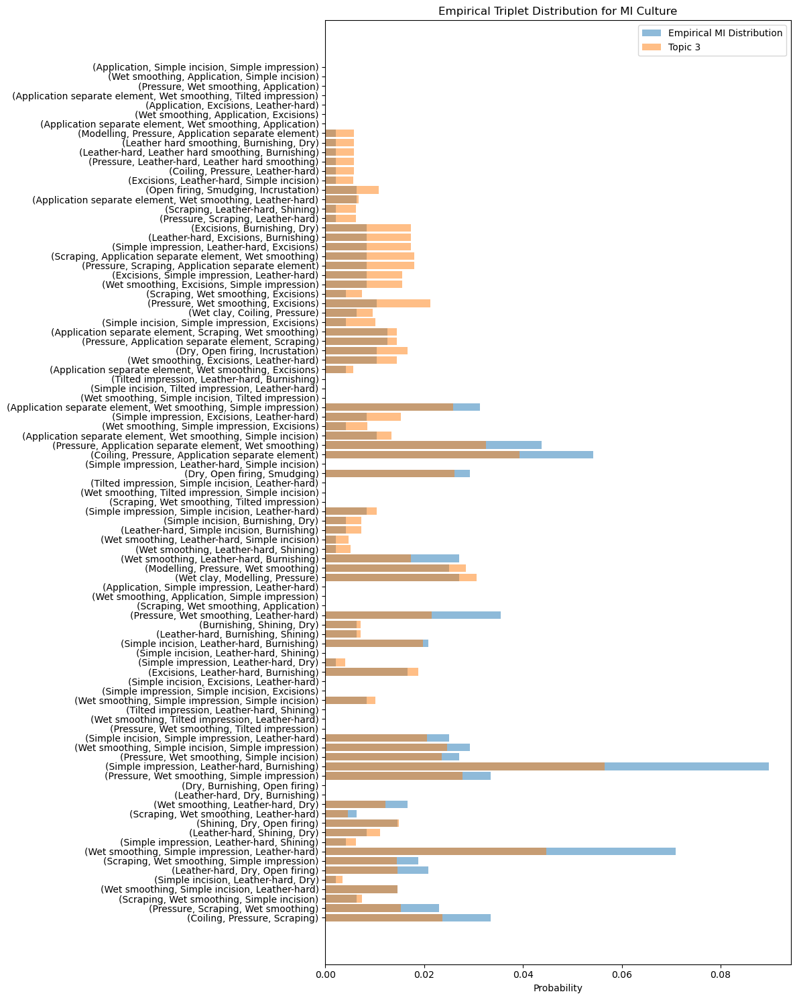

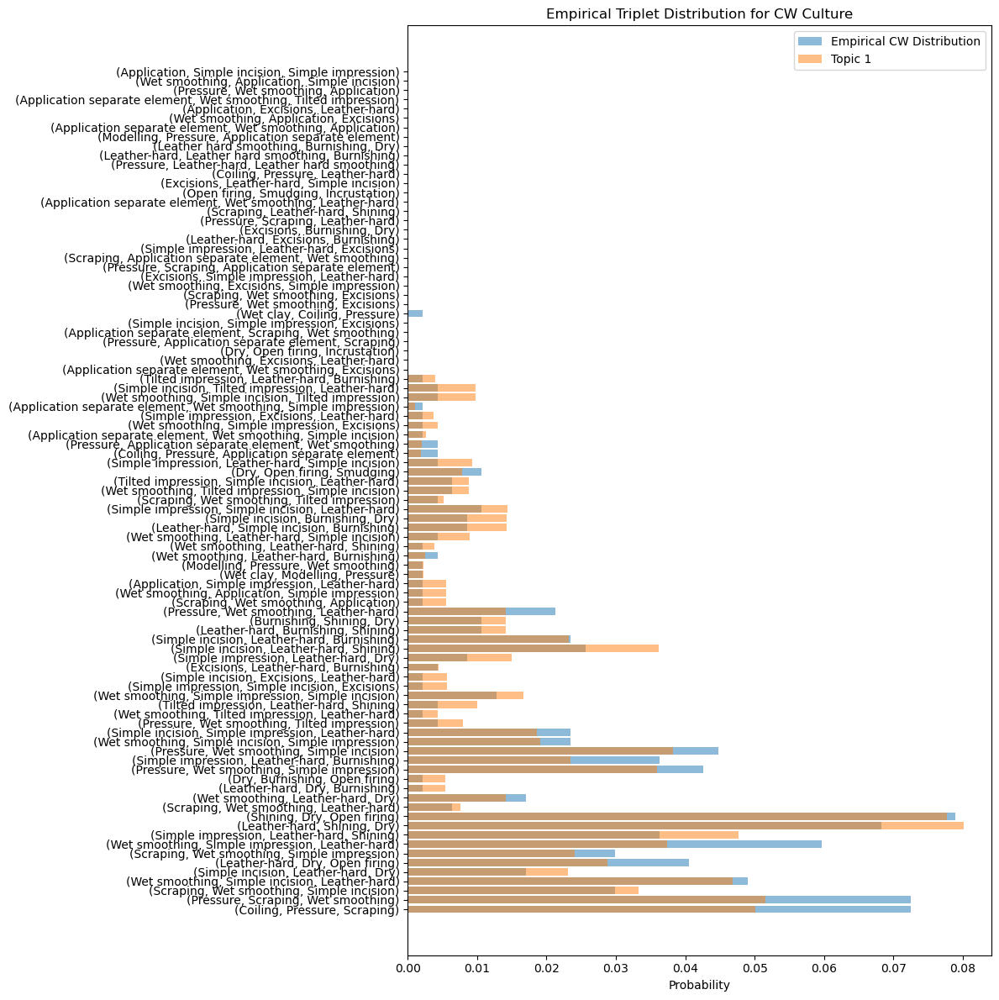

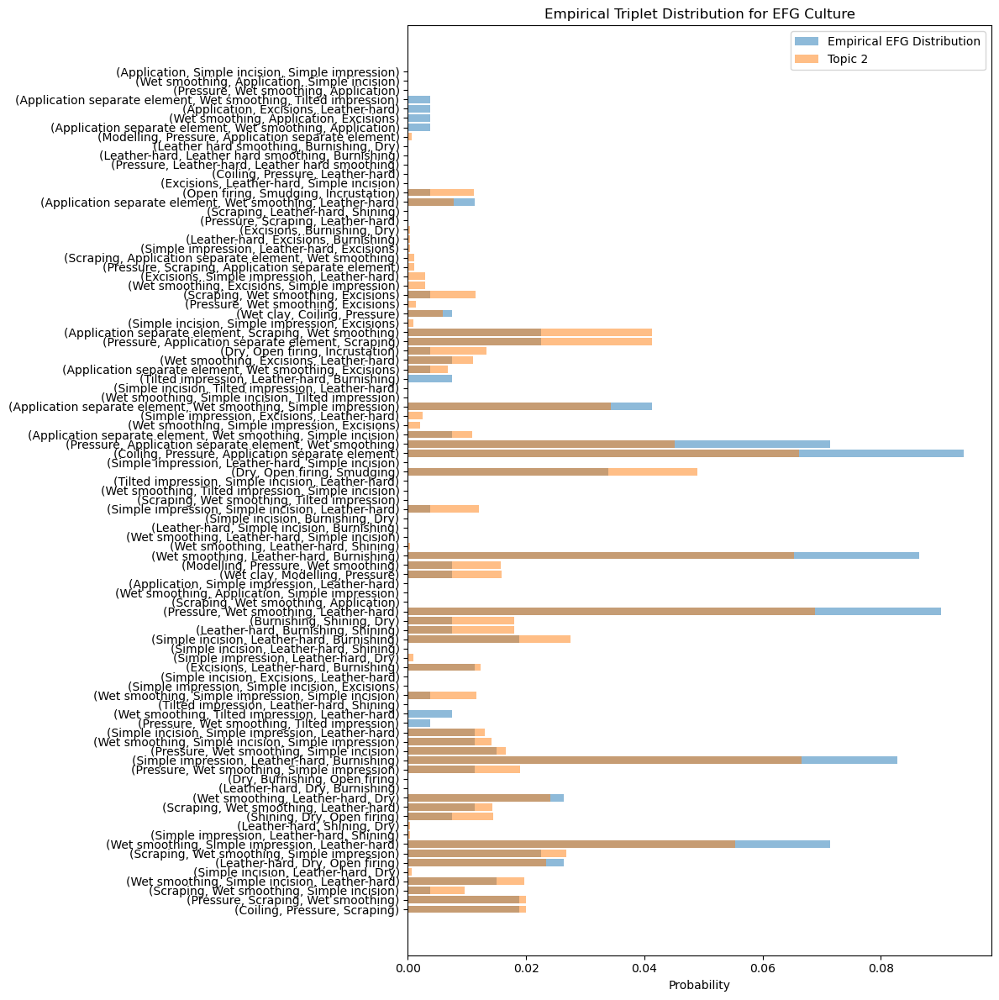

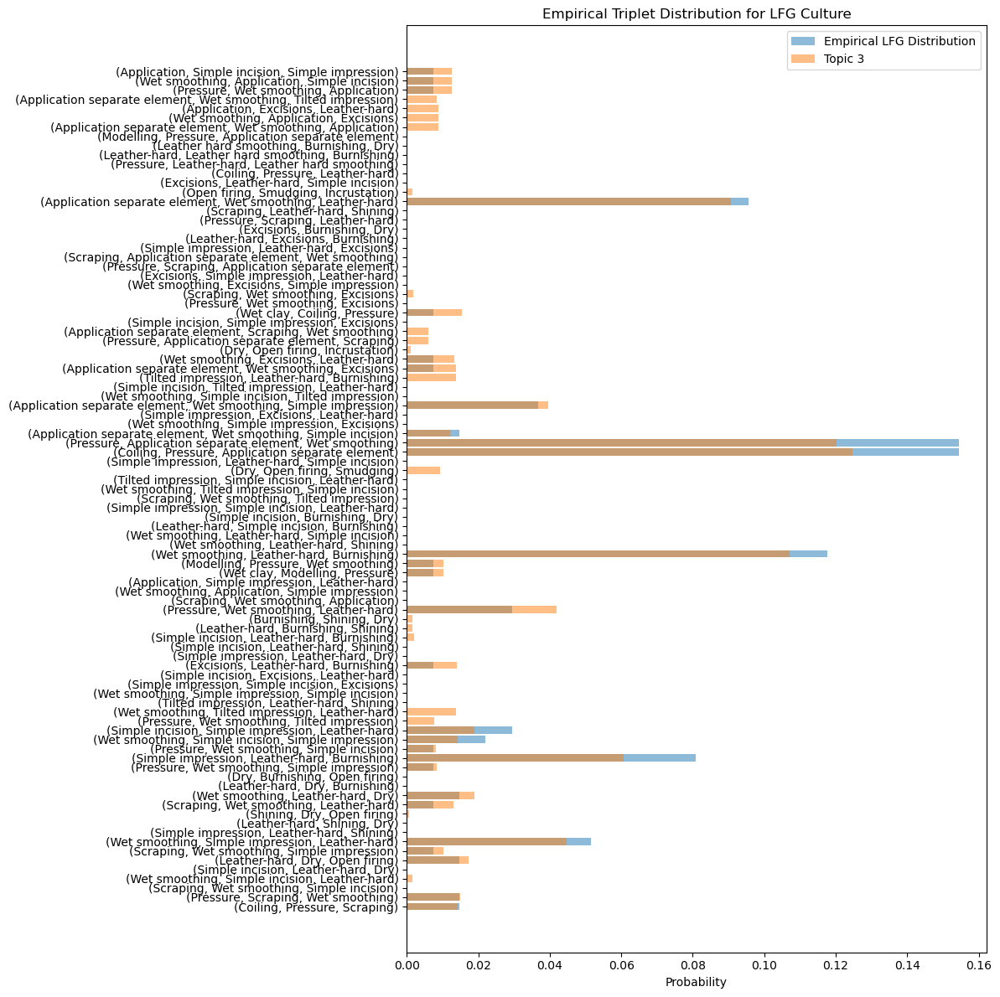

In [15]:
# plot the topic word distributions for each culture on the same plot with different colours
import matplotlib.pyplot as plt

#phi = lda_scratch.topic_word_dist

# empirical distributions for each culture
MI_triplets = []
triplets_per_vessel = []
for doc in mi_docs:
    MI_triplets.extend(doc['triplets'])
    triplets_per_vessel.append(doc['num_triplets'])
MI_counts = Counter(MI_triplets)
MI_total = sum(MI_counts.values())
MI_dist = np.array([MI_counts.get(triplet, 0) / MI_total for triplet in features_original])

EFG_triplets = []
triplets_per_vessel = []
for doc in efg_docs:
    EFG_triplets.extend(doc['triplets'])
    triplets_per_vessel.append(doc['num_triplets'])
EFG_counts = Counter(EFG_triplets)
EFG_total = sum(EFG_counts.values())
EFG_dist = np.array([EFG_counts.get(triplet, 0) / EFG_total for triplet in features_original])

LFG_triplets = []
triplets_per_vessel = []
for doc in lfg_docs:
    LFG_triplets.extend(doc['triplets'])
    triplets_per_vessel.append(doc['num_triplets'])
LFG_counts = Counter(LFG_triplets)
LFG_total = sum(LFG_counts.values())
print("LFG total:", LFG_total)
print("LFG counts for original features:", [LFG_counts.get(triplet, 0) for triplet in features_original])
LFG_dist = np.array([LFG_counts.get(triplet, 0) / LFG_total for triplet in features_original])  

CW_triplets = []
triplets_per_vessel = []
for doc in cw_docs:
    CW_triplets.extend(doc['triplets'])
    triplets_per_vessel.append(doc['num_triplets'])
CW_counts = Counter(CW_triplets)
CW_total = sum(CW_counts.values())
CW_dist = np.array([CW_counts.get(triplet, 0) / CW_total for triplet in features_original])


# calculate using the JS divergence the similarity between the empirical distribution and the topic distribution for each culture
# which is the best matching between empirical and topic distribution
from scipy.spatial.distance import jensenshannon    
def js_divergence(p, q):
    return jensenshannon(p, q)**2  # square to get the divergence   
js_MI = [js_divergence(MI_dist, phi[k]) for k in range(NUM_CULTURES)]
js_CW = [js_divergence(CW_dist, phi[k]) for k in range(NUM_CULTURES)]
js_EFG = [js_divergence(EFG_dist, phi[k]) for k in range(NUM_CULTURES)]
js_LFG = [js_divergence(LFG_dist, phi[k]) for k in range(NUM_CULTURES)]

print("\nJensen-Shannon Divergence between empirical and topic distributions:")
print(f"MI: {js_MI}")
print(f"CW: {js_CW}")
print(f"EFG: {js_EFG}")
print(f"LFG: {js_LFG}") 

MI_index = np.argmin(js_MI)
CW_index = np.argmin(js_CW) 
EFG_index = np.argmin(js_EFG)
LFG_index = np.argmin(js_LFG)

culture_mapping = {
    'MI': MI_index,
    'CW': CW_index,
    'EFG': EFG_index,
    'LFG': LFG_index
}

plt.figure(figsize=(12, 15))
plt.barh(range(len(features_original)), MI_dist, alpha=0.5, label='Empirical MI Distribution')
plt.barh(range(len(features_original)), phi[MI_index], alpha=0.5, label='Topic 3')
plt.xlabel('Probability')
plt.yticks(range(len(features_original)), features_original)
plt.title('Empirical Triplet Distribution for MI Culture')
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 12))
plt.barh(range(len(features_original)), CW_dist, alpha=0.5, label='Empirical CW Distribution')
plt.barh(range(len(features_original)), phi[CW_index], alpha=0.5, label='Topic 1')
plt.xlabel('Probability')
plt.yticks(range(len(features_original)), features_original)
plt.title('Empirical Triplet Distribution for CW Culture')
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 12))
plt.barh(range(len(features_original)), EFG_dist, alpha=0.5, label='Empirical EFG Distribution')
plt.barh(range(len(features_original)), phi[EFG_index], alpha=0.5, label='Topic 2')
plt.xlabel('Probability')
plt.yticks(range(len(features_original)), features_original)
plt.title('Empirical Triplet Distribution for EFG Culture')
plt.legend()
plt.tight_layout()
plt.show()  

plt.figure(figsize=(12, 12))
plt.barh(range(len(features_original)), LFG_dist, alpha=0.5, label='Empirical LFG Distribution')
plt.barh(range(len(features_original)), phi[LFG_index], alpha=0.5, label='Topic 3')
plt.xlabel('Probability')
plt.yticks(range(len(features_original)), features_original)
plt.title('Empirical Triplet Distribution for LFG Culture')
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
lda_scratch_2 = LDA_manual(n_topics=2, n_iter=100, random_state=42)
lda_scratch_2.fit(X_resampled_3)


In [ ]:

phi = lda_scratch.topic_word_dist


# empirical distributions for each culture
FBW_triplets = []
triplets_per_vessel = []
for doc in fbw_docs:
    FBW_triplets.extend([triplet for triplet in doc['triplets'] if triplet not in most_common_triplets])
    triplets_per_vessel.append(doc['num_triplets'])
FBW_counts = Counter(FBW_triplets)
FBW_total = sum(FBW_counts.values())
FBW_dist = np.array([FBW_counts.get(triplet, 0) / FBW_total for triplet in features_original])

CW_triplets = []
triplets_per_vessel = []
for doc in cw_docs: 
    CW_triplets.extend(doc['triplets'])
    triplets_per_vessel.append(doc['num_triplets'])
CW_counts = Counter(CW_triplets)
CW_total = sum(CW_counts.values())
CW_dist = np.array([CW_counts.get(triplet, 0) / CW_total for triplet in features_original])  


plt.figure(figsize=(12, 12))
plt.barh(range(len(features_resampled_3)), FBW_dist, alpha=0.5, label='Empirical FBW Distribution')
plt.barh(range(len(features_resampled_3)), phi[1], alpha=0.5, label='Topic 1')
plt.xlabel('Probability')
plt.yticks(range(len(features_resampled_3)), features_original)
plt.title('Empirical Triplet Distribution for FBW Culture')
plt.legend()
plt.tight_layout()
plt.show()  
plt.figure(figsize=(12, 12))
plt.barh(range(len(features_resampled_3)), CW_dist, alpha=0.5, label='Empirical CW Distribution')
plt.barh(range(len(features_resampled_3)), phi[0], alpha=0.5, label='Topic 0')
plt.xlabel('Probability')
plt.yticks(range(len(features_resampled_3)), features_resampled_3)
plt.title('Empirical Triplet Distribution for CW Culture')
plt.legend()
plt.tight_layout()  
plt.show()  


# Model Evaluation

In [ ]:
new_sample_doc = [[ 
    "(Pressure, Wet smoothing, Simple impression)",
    "(Wet smoothing, Simple impression, Leather-hard)",
    "(Simple impression, Leather-hard, Burnishing)",
    "(Leather-hard, Burnishing, Dry)",
    "(Burnishing, Dry, Open firing)"
],  [  
    "(Coiling, Pressure, Scraping)",
    "(Pressure, Scraping, Wet smoothing)",
    "(Scraping, Wet smoothing, Tilted impression)",
    "(Wet smoothing, Tilted impression, Simple incision)",
    "(Tilted impression, Simple incision, Leather-hard)",
    "(Simple incision, Leather-hard, Dry)",
    "(Leather-hard, Dry, Open firing)"
] , [
    "(Pressure, Wet smoothing, Simple impression)",
    "(Wet smoothing, Tilted impression, Simple incision)",
    "(Tilted impression, Simple incision, Leather-hard)",
    "(Simple incision, Leather-hard, Dry)",
    "(Leather-hard, Dry, Open firing)"
] , [
    "(Coiling, Pressure, Scraping)",
    "(Pressure, Scraping, Wet smoothing)",
    "(Wet smoothing, Simple impression, Leather-hard)",
    "(Simple impression, Leather-hard, Burnishing)",
    "(Leather-hard, Burnishing, Dry)",
    "(Burnishing, Dry, Open firing)"
], 
["(Wet clay, Modelling, Coiling)","(Modelling, Coiling, Pressure)","(Coiling, Pressure, Wet smoothing)","(Pressure, Wet smoothing, Leather-hard)","(Wet smoothing, Leather-hard, Burnishing)","(Leather-hard, Burnishing, Dry)","(Burnishing, Dry, Open firing)"]
]

In [ ]:
triplet_pattern = re.compile(r"\([^()]*?,[^()]*?,[^()]*?\)")
def triplet_tokenizer(text):
    return [normalize_triplet(t) for t in triplet_pattern.findall(text)]

def classify_new_vessel(new_triplets, trained_lda, vocab, culture_mapping=None):
    # Vectorize using the model's vocabulary order
    vectorizer = CountVectorizer(
        tokenizer=triplet_tokenizer,
        lowercase=False,
        token_pattern=None,
        vocabulary=list(vocab)
    )
    tmp_trip = [words for words in new_triplets if words in vocab]
    new_triplets = tmp_trip
    vessel_text = ' '.join(new_triplets)
    print("vessel_text", vessel_text)
    X_new = vectorizer.transform([vessel_text])
    print("X_new", X_new)
    topic_probs = trained_lda.transform(X_new)[0]

    dominant_topic = int(topic_probs.argmax())
    max_prob = float(topic_probs.max())
    if culture_mapping:
        predicted_culture = culture_mapping.get(dominant_topic, f"Topic_{dominant_topic}")
    else:
        predicted_culture = f"Topic_{dominant_topic}"
    confidence = 'High' if max_prob >= 0.6 else ('Medium' if max_prob >= 0.4 else 'Low')
    return {
        'predicted_culture': predicted_culture,
        'topic_probabilities': topic_probs,
        'max_probability': max_prob,
        'confidence': confidence,
        'dominant_topic': dominant_topic
    }


# Example:
new_vessel = efg_docs[-20:][0]['triplets']
print(new_vessel)
print(culture_mapping)
result = classify_new_vessel(new_vessel, lda_scratch, vocabulary, culture_mapping=culture_mapping)

In [ ]:
vocab_dict = dict(zip(vocabulary, np.arange(len(vocabulary))))

print(vocab_dict)

In [ ]:
print("\nNew vessel classification:")
print(f"Triplets: {new_vessel}")
print(f"Predicted Culture: {result['predicted_culture']}")
print(f"Topic Probabilities: {result['topic_probabilities']}")
print(f"Dominant Topic: {result['dominant_topic']}")
print(f"confidence: {result['confidence']} (max prob: {result['max_probability']:.3f})")